In [ ]:
# Garment Production Intelligence

## 04 — Statistical Productivity Analysis

### Business Problem
Management wants to understand whether
productivity differences between the sewing
and finishing departments are statistically meaningful.

### Statistical Methods
1. Descriptive statistics
2. Hypothesis testing
3. Confidence intervals
4. Regression analysis

### First Research Question
Is average actual productivity different
between the sewing and finishing departments?

In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from pathlib import Path

# Identify project directory
project_dir = Path.cwd()

if project_dir.name == "notebooks":
    project_dir = project_dir.parent

# Locate cleaned dataset
file_path = (
    project_dir
    / "data"
    / "processed"
    / "garments_productivity_cleaned.csv"
)

# Load dataset
df = pd.read_csv(file_path)

print("Dataset loaded successfully!")
print("Total rows:", df.shape[0])
print("Total columns:", df.shape[1])

df.head()


Dataset loaded successfully!
Total rows: 1197
Total columns: 15


,date,quarter,department,day,team,targeted_productivity,smv,wip,over_time,incentive,idle_time,idle_men,no_of_style_change,no_of_workers,actual_productivity
0,2015-01-01,Quarter1,sewing,Thursday,8,0.80,26.16,1108.0,7080,98,0.0,0,0,59.0,0.940725
1,2015-01-01,Quarter1,finishing,Thursday,1,0.75,3.94,NaN,960,0,0.0,0,0,8.0,0.886500
2,2015-01-01,Quarter1,sewing,Thursday,11,0.80,11.41,968.0,3660,50,0.0,0,0,30.5,0.800570
3,2015-01-01,Quarter1,sewing,Thursday,12,0.80,11.41,968.0,3660,50,0.0,0,0,30.5,0.800570
4,2015-01-01,Quarter1,sewing,Thursday,6,0.80,25.90,1170.0,1920,50,0.0,0,0,56.0,0.800382


In [2]:

# Separate productivity by department

sewing = df.loc[
    df["department"] == "sewing",
    "actual_productivity"
]

finishing = df.loc[
    df["department"] == "finishing",
    "actual_productivity"
]

print("SEWING")
print("Observations:", len(sewing))
print(f"Average productivity: {sewing.mean():.2%}")
print(f"Standard deviation: {sewing.std():.4f}")

print("\nFINISHING")
print("Observations:", len(finishing))
print(f"Average productivity: {finishing.mean():.2%}")
print(f"Standard deviation: {finishing.std():.4f}")


SEWING
Observations: 691
Average productivity: 72.20%
Standard deviation: 0.1548

FINISHING
Observations: 506
Average productivity: 75.30%
Standard deviation: 0.1970


In [3]:

# Separate productivity observations by department

sewing = df.loc[
    df["department"] == "sewing",
    "actual_productivity"
].dropna()

finishing = df.loc[
    df["department"] == "finishing",
    "actual_productivity"
].dropna()

# Display descriptive statistics
print("SEWING DEPARTMENT")
print("Observations:", len(sewing))
print(f"Mean Productivity: {sewing.mean():.2%}")
print(f"Standard Deviation: {sewing.std():.4f}")

print("\nFINISHING DEPARTMENT")
print("Observations:", len(finishing))
print(f"Mean Productivity: {finishing.mean():.2%}")
print(f"Standard Deviation: {finishing.std():.4f}")


SEWING DEPARTMENT
Observations: 691
Mean Productivity: 72.20%
Standard Deviation: 0.1548

FINISHING DEPARTMENT
Observations: 506
Mean Productivity: 75.30%
Standard Deviation: 0.1970


## Welch's Two-Sample t-Test

### Research Question
Is average actual productivity different between
the sewing and finishing departments?

### Null Hypothesis (H0)
The population mean productivity of sewing
and finishing is equal.

H0: μ_sewing = μ_finishing

### Alternative Hypothesis (H1)
The population mean productivity is different.

H1: μ_sewing ≠ μ_finishing

### Significance Level
α = 0.05

### Statistical Method
Welch's two-sample t-test.

In [5]:

# Welch's two-sample t-test

t_statistic, p_value = stats.ttest_ind(
    sewing,
    finishing,
    equal_var=False,
    alternative="two-sided"
)

alpha = 0.05

print("WELCH'S TWO-SAMPLE T-TEST")
print("-" * 40)

print(f"T-statistic: {t_statistic:.4f}")
print(f"P-value: {p_value:.6f}")
print(f"Significance level: {alpha}")

if p_value < alpha:
    print("Result: Reject H0")
    print("The department means differ statistically.")
else:
    print("Result: Fail to reject H0")
    print("Insufficient evidence of a difference.")


WELCH'S TWO-SAMPLE T-TEST
----------------------------------------
T-statistic: -2.9314
P-value: 0.003458
Significance level: 0.05
Result: Reject H0
The department means differ statistically.


## 95% Confidence Interval for Mean Productivity Difference

### Objective
Estimate the difference in average actual productivity
between sewing and finishing departments.

### Statistical Method
Welch's confidence interval for two independent means.

### Confidence Level
95%

### Difference Definition
Mean Sewing Productivity - Mean Finishing Productivity

### Limitation
This interval assumes independent observations.
Repeated observations from the same teams may
violate that assumption.

In [6]:

# Calculate Welch's 95% confidence interval

test_result = stats.ttest_ind(
    sewing,
    finishing,
    equal_var=False,
    alternative="two-sided"
)

# Obtain 95% confidence interval
ci = test_result.confidence_interval(
    confidence_level=0.95
)

# Difference in average productivity
mean_difference = sewing.mean() - finishing.mean()

print("95% CONFIDENCE INTERVAL")
print("-" * 45)

print(
    f"Mean Difference: "
    f"{mean_difference * 100:.2f} percentage points"
)

print(
    f"Lower Bound: "
    f"{ci.low * 100:.2f} percentage points"
)

print(
    f"Upper Bound: "
    f"{ci.high * 100:.2f} percentage points"
)

print(f"P-value: {test_result.pvalue:.6f}")


95% CONFIDENCE INTERVAL
---------------------------------------------
Mean Difference: -3.09 percentage points
Lower Bound: -5.17 percentage points
Upper Bound: -1.02 percentage points
P-value: 0.003458


## Visualization of the Mean Productivity Difference

### Objective
Visualize the estimated productivity difference between
the sewing and finishing departments with a 95%
confidence interval.

The difference is calculated as:
Sewing Mean - Finishing Mean.

This is an exploratory confidence interval because
the observations may not be independent.

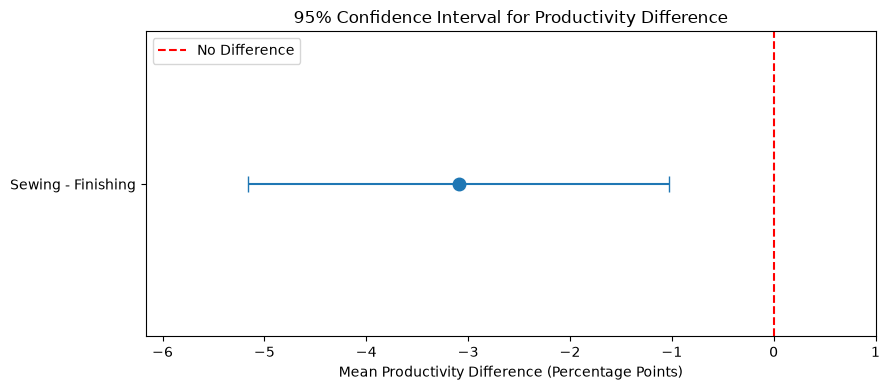

In [7]:

# Visualize Welch's 95% confidence interval

import matplotlib.pyplot as plt

# Convert values to percentage points
difference_pp = mean_difference * 100
lower_pp = ci.low * 100
upper_pp = ci.high * 100

# Calculate distances from estimate to CI bounds
lower_error = difference_pp - lower_pp
upper_error = upper_pp - difference_pp

fig, ax = plt.subplots(figsize=(9, 4))

ax.errorbar(
    x=[difference_pp],
    y=[0],
    xerr=[[lower_error], [upper_error]],
    fmt="o",
    capsize=6,
    markersize=9
)

# Reference line for no difference
ax.axvline(
    x=0,
    color="red",
    linestyle="--",
    label="No Difference"
)

ax.set_yticks([0])
ax.set_yticklabels(["Sewing - Finishing"])

ax.set_xlabel("Mean Productivity Difference (Percentage Points)")
ax.set_title("95% Confidence Interval for Productivity Difference")

ax.set_xlim(
    min(lower_pp - 1, -1),
    max(upper_pp + 1, 1)
)

ax.legend()
plt.tight_layout()
plt.show()


### Statistical Interpretation

The estimated mean productivity difference between
sewing and finishing is -3.09 percentage points.

The 95% Welch confidence interval ranges from
-5.17 to -1.02 percentage points.

The interval excludes zero, consistent with the
exploratory Welch t-test result (p = 0.003458).

Finishing recorded higher average productivity
than sewing in the observed dataset.

However, the confidence interval assumes independent
observations. Repeated observations from production
teams may violate this assumption.

Further analysis accounting for team-level dependence
is needed before drawing stronger statistical conclusions.